# Klasifikasi Tingkat Kematangan Mangga dengan MobileNetV4



### 1. Sumber dan batas data

Penelitian menggunakan Mango Shelf-Life Dataset dari Mashkoor dan Hakim (2024), berisi citra mangga White Chaunsa Late dari Multan, Pakistan, dengan lisensi CC BY 4.0.

Sumber: https://data.mendeley.com/datasets/rk4mm635rn/1

Tiga kelas yang digunakan adalah Unripe (mentah), Fully ripe (matang), dan Overripe (terlalu matang). Kelas semi-ripe dan perished tidak digunakan.

Gambar identik dihapus dan gambar mirip dikelompokkan sebelum pembagian data. Pengelompokan menggunakan pHash belum menjamin semua foto buah yang sama teridentifikasi. Gunakan gambar asli; jumlah gambar dan rasio pembagian mengikuti hasil pembacaan notebook.

In [ ]:
%pip -q install "timm>=1.0.12,<1.1" "ImageHash>=4.3,<5" "libarchive-c>=5,<6" requests scikit-learn pandas matplotlib seaborn tqdm


In [ ]:
from pathlib import Path
import os, sys, json, random, hashlib, time, shutil, re, subprocess, gc, zipfile
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests, imagehash, timm, torch, torchvision
from PIL import Image, ImageOps
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from torchvision.transforms import InterpolationMode
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from tqdm.auto import tqdm
from IPython.display import display, Markdown

AUTHOR_NAMES = "Felix Ferdinad, Melvyn Benaya Wijaya"
STUDENT_IDS = "535230123, 535230047"
COLAB_URL = ""  # Isi URL Share notebook setelah disimpan di Colab.
RUN_NAME = "test_02"  # Ganti untuk eksperimen dengan konfigurasi baru.
SAVE_TO_DRIVE = True
DATA_MODE = "auto"       # "auto", "upload", atau "folder"
LOCAL_DATA_DIR = "/content/mango_original"  # Dipakai bila DATA_MODE="folder".
LOCAL_ARCHIVE_PATH = ""  # Opsional: path ZIP/RAR di Drive; menghindari upload browser.
GROUP_CSV = ""          # Opsional CSV: relative_path, fruit_id; seluruh gambar harus tercakup.

SEED = 42
MODEL_NAME = "mobilenetv4_conv_small.e2400_r224_in1k"
CLASS_NAMES = ["unripe", "fully_ripe", "overripe"]
DISPLAY_NAMES = ["Mentah", "Matang", "Terlalu matang"]
IMG_SIZE = 224
BATCH_SIZE = 32          # Turunkan ke 16 jika CUDA out of memory.
NUM_WORKERS = 0          # Ubah ke 0 jika worker mengalami masalah.
HEAD_EPOCHS = 3
FINETUNE_EPOCHS = 7
HEAD_LR = 1e-3
FINETUNE_LR = 3e-5
FINETUNE_HEAD_LR = 3e-4
WEIGHT_DECAY = 1e-4
BRIGHTNESS = 0.15
CONTRAST = 0.15
PHASH_DISTANCE = 4       # Kelompokkan kandidat pHash dengan Hamming distance <= 4.
RUN_AUGMENTED = True
RUN_FINAL_TEST = False  # Aktifkan setelah konfigurasi final dikunci.

assert HEAD_EPOCHS > 0 and FINETUNE_EPOCHS >= 0
assert BATCH_SIZE >= 2
assert DATA_MODE in {"auto", "upload", "folder"}

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("CPU aktif. Untuk training lebih cepat, pilih runtime GPU sebelum melanjutkan.")
print("torch:", torch.__version__, "torchvision:", torchvision.__version__, "timm:", timm.__version__)


Device: cuda
GPU: Tesla T4
torch: 2.14.1+cu130 torchvision: 0.29.1+cu130 timm: 1.0.31


### 2. Lokasi hasil dan pencatatan lingkungan
Checkpoint disimpan setiap epoch. Gunakan RUN_NAME dan konfigurasi yang sama untuk melanjutkan training atau membuka hasil yang sudah selesai. Jika data atau hyperparameter berubah, gunakan RUN_NAME baru.

Dua eksperimen membandingkan model tanpa augmentasi dan dengan augmentasi, menggunakan seed yang sama.

In [ ]:
IN_COLAB = "google.colab" in sys.modules or bool(os.environ.get("COLAB_RELEASE_TAG"))
if SAVE_TO_DRIVE:
    if not IN_COLAB:
        raise RuntimeError("Jalankan di Colab atau ubah SAVE_TO_DRIVE=False untuk lingkungan lokal.")
    from google.colab import drive
    drive.mount("/content/drive")
    OUTPUT_DIR = Path("/content/drive/MyDrive/UAS_DeepLearning_Mangga") / RUN_NAME
else:
    OUTPUT_DIR = Path("/content/mango_results" if IN_COLAB else "mango_results") / RUN_NAME
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
WORK_DIR = Path("/content/mango_work" if IN_COLAB else "mango_work")
WORK_DIR.mkdir(parents=True, exist_ok=True)
DATASET_URL = "https://data.mendeley.com/datasets/rk4mm635rn/1"
ARCHIVE_URL = "https://data.mendeley.com/public-api/zip/rk4mm635rn/download/1"
environment = {
    "python": sys.version, "torch": torch.__version__, "torchvision": torchvision.__version__,
    "timm": timm.__version__, "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
}
print("Hasil:", OUTPUT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Hasil: /content/drive/MyDrive/UAS_DeepLearning_Mangga/test_02


### 3. Upload dan ekstraksi dataset



In [ ]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

def extract_archive(archive, destination):
    # libarchive membaca ZIP/RAR/7z, termasuk arsip di dalam arsip.
    import libarchive
    destination = Path(destination).resolve()
    destination.mkdir(parents=True, exist_ok=True)
    with libarchive.file_reader(str(archive)) as entries:
        for entry in entries:
            name = str(entry.pathname).replace(chr(92), "/")
            target = (destination / name).resolve()
            if not target.is_relative_to(destination):
                raise ValueError(f"Path arsip tidak valid: {name}")
            if entry.isdir:
                target.mkdir(parents=True, exist_ok=True)
            elif entry.isfile:
                target.parent.mkdir(parents=True, exist_ok=True)
                with target.open("wb") as f:
                    for block in entry.get_blocks():
                        f.write(block)

def download_archive(url, path):
    temp = path.with_suffix(".part")
    try:
        with requests.get(url, stream=True, timeout=(30, 180), headers={"User-Agent": "Mozilla/5.0"}) as r:
            r.raise_for_status()
            if "text/html" in r.headers.get("content-type", ""):
                raise RuntimeError("Server mengirim halaman HTML, bukan arsip dataset.")
            total = int(r.headers.get("content-length", 0))
            with temp.open("wb") as f, tqdm(total=total or None, unit="B", unit_scale=True, desc="Dataset") as bar:
                for chunk in r.iter_content(1024 * 1024):
                    if chunk:
                        f.write(chunk); bar.update(len(chunk))
        temp.replace(path)
    except Exception:
        temp.unlink(missing_ok=True)
        raise

if DATA_MODE == "folder":
    DATA_ROOT = Path(LOCAL_DATA_DIR).expanduser().resolve()
    if not DATA_ROOT.is_dir():
        raise FileNotFoundError(f"Folder tidak ditemukan: {DATA_ROOT}")
else:
    if LOCAL_ARCHIVE_PATH:
        archives = [Path(LOCAL_ARCHIVE_PATH)]
    elif DATA_MODE == "upload":
        if not IN_COLAB:
            raise RuntimeError("Untuk lokal gunakan LOCAL_ARCHIVE_PATH atau DATA_MODE='folder'.")
        from google.colab import files
        uploaded = files.upload()
        archives = []
        for name, content in uploaded.items():
            path = WORK_DIR / Path(name).name
            path.write_bytes(content); archives.append(path)
        del uploaded
        if not archives:
            raise RuntimeError("Belum ada arsip yang diunggah.")
    else:
        path = WORK_DIR / "mango_mendeley_v1.zip"
        if not path.exists():
            try:
                download_archive(ARCHIVE_URL, path)
            except Exception as e:
                raise RuntimeError(
                    f"Unduhan otomatis gagal ({type(e).__name__}: {e}). "
                    f"Unduh Download All dari {DATASET_URL}, lalu gunakan DATA_MODE='upload' "
                    "atau isi LOCAL_ARCHIVE_PATH. Tidak perlu akun Kaggle."
                ) from e
        archives = [path]
    # Pisahkan ekstraksi berdasarkan hash arsip; tidak mencampur dataset baru dengan cache lama.
    archive_digests = []
    for archive in archives:
        if not archive.is_file():
            raise FileNotFoundError(archive)
        with archive.open("rb") as f:
            archive_digests.append(hashlib.file_digest(f, "sha256").hexdigest())
    archive_key = hashlib.sha256("".join(sorted(archive_digests)).encode()).hexdigest()[:12]
    DATA_ROOT = WORK_DIR / f"extracted_{archive_key}"
    done = DATA_ROOT / "extraction_complete.txt"
    if not done.exists():
        if DATA_ROOT.exists():
            shutil.rmtree(DATA_ROOT)
        DATA_ROOT.mkdir(parents=True)
        for i, archive in enumerate(archives):
            extract_archive(archive, DATA_ROOT / f"source_{i}")
        processed = set()
        for depth in range(6):
            nested = [p for p in DATA_ROOT.rglob("*") if p.is_file()
                      and p.suffix.lower() in {".zip", ".rar", ".7z"} and str(p) not in processed]
            if not nested:
                break
            for archive in nested:
                extract_archive(archive, archive.parent / (archive.stem + "_extracted"))
                processed.add(str(archive))
        else:
            raise RuntimeError("Terlalu banyak tingkat arsip. Ekstrak manual dan gunakan DATA_MODE='folder'.")
        done.write_text("OK")
print("Root:", DATA_ROOT)
folder_counts = Counter(str(p.parent.relative_to(DATA_ROOT)) for p in DATA_ROOT.rglob("*")
                        if p.is_file() and p.suffix.lower() in IMAGE_EXTS and "__MACOSX" not in p.parts)
display(pd.DataFrame(folder_counts.items(), columns=["folder", "images"]).sort_values("folder").head(60))
if not folder_counts:
    raise RuntimeError("Tidak ditemukan gambar. Periksa ekstraksi dan sumber dataset.")


Root: /content/mango_work/extracted_024f90622183


,folder,images
3,source_0/Mango Shelf-Life Dataset/Fully Ripe,841
0,source_0/Mango Shelf-Life Dataset/Overripe,896
2,source_0/Mango Shelf-Life Dataset/Perished,184
4,source_0/Mango Shelf-Life Dataset/Semiripe,1157
1,source_0/Mango Shelf-Life Dataset/Unripe,1350


### 4. Baca label, audit gambar, dan hilangkan duplikasi identik
Label ditentukan dari nama folder. Jika nama folder berbeda atau hanya berupa angka, periksa label asli dataset lalu sesuaikan CLASS_FOLDER_MAP. Hasil pemeriksaan disimpan dalam file CSV.


In [ ]:
def normalize_name(s):
    return re.sub(r"[^a-z0-9]", "", s.lower())

# Kunci adalah nama folder yang sudah dinormalisasi (tanpa spasi/underscore/tanda baca).
CLASS_FOLDER_MAP = {
    "unripe": "unripe", "unripemango": "unripe", "unripemangoes": "unripe",
    "fullyripe": "fully_ripe", "fullyripemango": "fully_ripe", "fullyripemangoes": "fully_ripe",
    "ripe": "fully_ripe", "ripemango": "fully_ripe", "ripemangoes": "fully_ripe",
    "overripe": "overripe", "overripemango": "overripe", "overripemangoes": "overripe",
}
EXCLUDED_FOLDERS = {"semiripe", "semiripemango", "semiripemangoes", "perished", "perishedmango", "perishedmangoes", "rotten"}

def label_from_path(path):
    for component in reversed(path.relative_to(DATA_ROOT).parts[:-1]):
        normalized = re.sub(r"^\d+", "", normalize_name(component))
        if normalized in EXCLUDED_FOLDERS:
            return None, "excluded"
        if normalized in CLASS_FOLDER_MAP:
            return CLASS_FOLDER_MAP[normalized], "included"
    return None, "unrecognized"

rows, invalid, skipped = [], [], []
paths = sorted(p for p in DATA_ROOT.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTS
               and "__MACOSX" not in p.parts and not p.name.startswith("."))
for path in tqdm(paths, desc="Audit gambar"):
    label, status = label_from_path(path)
    rel = str(path.relative_to(DATA_ROOT))
    if label is None:
        skipped.append({"relative_path": rel, "reason": status}); continue
    try:
        with Image.open(path) as im:
            image = ImageOps.exif_transpose(im).convert("RGB")
            image.load()
            width, height = image.size
            digest = hashlib.sha256(f"{width}x{height}|".encode() + image.tobytes()).hexdigest()
            phash = str(imagehash.phash(image))
        rows.append({"path": str(path), "relative_path": rel, "class_name": label,
                     "label": CLASS_NAMES.index(label), "width": width, "height": height,
                     "pixel_sha256": digest, "phash": phash})
    except Exception as e:
        invalid.append({"relative_path": rel, "error": str(e)})

pd.DataFrame(invalid, columns=["relative_path", "error"]).to_csv(WORK_DIR / "invalid_images.csv", index=False)
pd.DataFrame(skipped, columns=["relative_path", "reason"]).to_csv(WORK_DIR / "skipped_images.csv", index=False)
raw_df = pd.DataFrame(rows)
if raw_df.empty:
    raise ValueError("Tidak ada kelas dikenali. Periksa folder di sel sebelumnya dan CLASS_FOLDER_MAP.")
if any(s["reason"] == "unrecognized" for s in skipped):
    print("Ada folder tidak dikenali; periksa skipped_images.csv. Jangan menebak label numerik.")
conflicts = raw_df.groupby("pixel_sha256")["label"].nunique()
conflicts = conflicts[conflicts > 1].index
if len(conflicts):
    raw_df[raw_df.pixel_sha256.isin(conflicts)].to_csv(WORK_DIR / "conflicting_labels.csv", index=False)
    raise ValueError("Gambar identik memiliki label berbeda. Periksa conflicting_labels.csv sebelum melanjutkan.")
duplicates = raw_df[raw_df.duplicated("pixel_sha256", keep="first")]
duplicates.to_csv(WORK_DIR / "duplicates_removed.csv", index=False)
df = raw_df.drop_duplicates("pixel_sha256").reset_index(drop=True)
counts = df.class_name.value_counts().reindex(CLASS_NAMES, fill_value=0)
display(counts.rename("images_after_exact_dedup").to_frame())
print(f"Dibaca: {len(raw_df)} | Duplikat dibuang: {len(duplicates)} | Rusak: {len(invalid)} | Dipakai: {len(df)}")
if (counts < 10).any():
    raise ValueError("Setiap kelas perlu minimal 10 gambar valid unik. Periksa label/sumber dataset.")


Audit gambar:   0%|          | 0/4428 [00:00<?, ?it/s]

,images_after_exact_dedup
class_name,
unripe,1350
fully_ripe,841
overripe,896


Dibaca: 3087 | Duplikat dibuang: 0 | Rusak: 0 | Dipakai: 3087


### 5. Kelompokkan foto mirip dan buat split sekitar 70:15:15
Data dibagi berdasarkan grup sebelum augmentasi. Setiap grup tetap utuh sehingga proporsi akhirnya bisa berbeda dari target. Pembagian mempertimbangkan jumlah gambar dan kelas.

In [ ]:
parent = list(range(len(df)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]; i = parent[i]
    return i
def union(a, b):
    a, b = find(a), find(b)
    if a != b:
        parent[max(a, b)] = min(a, b)

hashes = [int(h, 16) for h in df.phash]
near_pairs = []
for i in tqdm(range(len(df)), desc="Kelompok pHash"):
    for j in range(i):
        distance = (hashes[i] ^ hashes[j]).bit_count()
        if distance <= PHASH_DISTANCE:
            union(i, j)
            near_pairs.append({"image_a": df.at[j, "relative_path"], "image_b": df.at[i, "relative_path"], "distance": distance})
pd.DataFrame(near_pairs, columns=["image_a", "image_b", "distance"]).to_csv(WORK_DIR / "near_duplicate_candidates.csv", index=False)

if GROUP_CSV:
    groups = pd.read_csv(GROUP_CSV, dtype=str)
    required = {"relative_path", "fruit_id"}
    if not required.issubset(groups.columns) or groups.relative_path.duplicated().any():
        raise ValueError("GROUP_CSV perlu kolom relative_path unik dan fruit_id.")
    lookup = groups.set_index("relative_path").fruit_id
    fruit_ids = df.relative_path.map(lookup)
    if fruit_ids.isna().any() or fruit_ids.str.strip().eq("").any():
        raise ValueError("GROUP_CSV harus memuat ID buah/sesi seluruh gambar yang dipakai.")
    for _, indices in fruit_ids.groupby(fruit_ids).groups.items():
        indices = list(indices)
        for i in indices[1:]:
            union(indices[0], i)
df["group_id"] = [f"g{find(i):06d}" for i in range(len(df))]
print("Grup:", df.group_id.nunique(), "| Pasangan kandidat mirip:", len(near_pairs))

def choose_group_split(frame, train_fraction, seed):
    splitter = GroupShuffleSplit(n_splits=128, train_size=train_fraction, random_state=seed)
    best = None
    expected = frame.label.value_counts().reindex(range(len(CLASS_NAMES)), fill_value=0).to_numpy()
    if frame.group_id.nunique() < 3:
        raise ValueError("Terlalu sedikit grup. Audit foto mirip / ID buah sebelum split.")
    for left, right in splitter.split(frame, frame.label, groups=frame.group_id):
        a = frame.iloc[left].label.value_counts().reindex(range(len(CLASS_NAMES)), fill_value=0).to_numpy()
        b = frame.iloc[right].label.value_counts().reindex(range(len(CLASS_NAMES)), fill_value=0).to_numpy()
        if min(a.min(), b.min()) == 0:
            continue
        score = np.abs(a / expected - train_fraction).mean() + abs(len(left) / len(frame) - train_fraction)
        if best is None or score < best[0]:
            best = (score, left, right)
    if best is None:
        raise ValueError("Tidak ada split dengan semua kelas. Audit grup dan tambahkan data bila perlu.")
    return frame.iloc[best[1]].copy(), frame.iloc[best[2]].copy()

train_df, remaining_df = choose_group_split(df, 0.70, SEED)
val_df, test_df = choose_group_split(remaining_df, 0.50, SEED + 1)
parts = {"train": train_df, "val": val_df, "test": test_df}
for split, frame in parts.items():
    frame["split"] = split
manifest = pd.concat(parts.values()).sort_values("relative_path").reset_index(drop=True)
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    assert set(parts[a].group_id).isdisjoint(set(parts[b].group_id))
    assert set(parts[a].pixel_sha256).isdisjoint(set(parts[b].pixel_sha256))
split_summary = pd.crosstab(manifest.class_name, manifest.split).reindex(CLASS_NAMES)[["train", "val", "test"]]
display(split_summary)
print("Rasio aktual:", manifest.split.value_counts(normalize=True).round(4).to_dict())
manifest_identity = manifest[["relative_path", "class_name", "pixel_sha256", "group_id", "split"]].to_csv(index=False)
DATA_FINGERPRINT = hashlib.sha256(manifest_identity.encode()).hexdigest()
experiment_config = {
    "seed": SEED, "model": MODEL_NAME, "classes": CLASS_NAMES, "image_size": IMG_SIZE,
    "batch_size": BATCH_SIZE, "head_epochs": HEAD_EPOCHS, "finetune_epochs": FINETUNE_EPOCHS,
    "head_lr": HEAD_LR, "finetune_lr": FINETUNE_LR, "finetune_head_lr": FINETUNE_HEAD_LR,
    "weight_decay": WEIGHT_DECAY, "brightness": BRIGHTNESS, "contrast": CONTRAST,
    "phash_distance": PHASH_DISTANCE, "dataset_fingerprint": DATA_FINGERPRINT,
    "torch": torch.__version__, "torchvision": torchvision.__version__, "timm": timm.__version__,
    "num_workers": NUM_WORKERS, "dropout": 0.2,
}
CONFIG_HASH = hashlib.sha256(json.dumps(experiment_config, sort_keys=True).encode()).hexdigest()
config_path = OUTPUT_DIR / "config.json"
if config_path.exists():
    previous = json.loads(config_path.read_text())
    if previous["config_hash"] != CONFIG_HASH:
        raise RuntimeError("Konfigurasi/data/versi library berbeda dari run tersimpan. Gunakan RUN_NAME baru.")
config_path.write_text(json.dumps({"config_hash": CONFIG_HASH, **experiment_config}, indent=2))
(OUTPUT_DIR / "environment.json").write_text(json.dumps(environment, indent=2))
(OUTPUT_DIR / "requirements_resolved.txt").write_text(subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True))
(OUTPUT_DIR / "identity.json").write_text(json.dumps({"names": AUTHOR_NAMES, "student_ids": STUDENT_IDS, "colab_url": COLAB_URL}, indent=2))
manifest.to_csv(OUTPUT_DIR / "split_manifest.csv", index=False)
split_summary.to_csv(OUTPUT_DIR / "dataset_split_summary.csv")
for audit_name in ["invalid_images.csv", "skipped_images.csv", "duplicates_removed.csv", "near_duplicate_candidates.csv"]:
    shutil.copy2(WORK_DIR / audit_name, OUTPUT_DIR / audit_name)
audit_info = {"valid_before_dedup": len(raw_df), "exact_duplicates_removed": len(duplicates),
              "invalid_images": len(invalid), "used_images": len(df), "groups": df.group_id.nunique(),
              "near_candidate_pairs": len(near_pairs), "fruit_ids_provided": bool(GROUP_CSV)}
(OUTPUT_DIR / "data_audit.json").write_text(json.dumps(audit_info, indent=2))


Kelompok pHash:   0%|          | 0/3087 [00:00<?, ?it/s]

Grup: 2327 | Pasangan kandidat mirip: 944


split,train,val,test
class_name,,,
unripe,945,204,201
fully_ripe,587,129,125
overripe,630,130,136


Rasio aktual: {'train': 0.7004, 'val': 0.15, 'test': 0.1497}


191

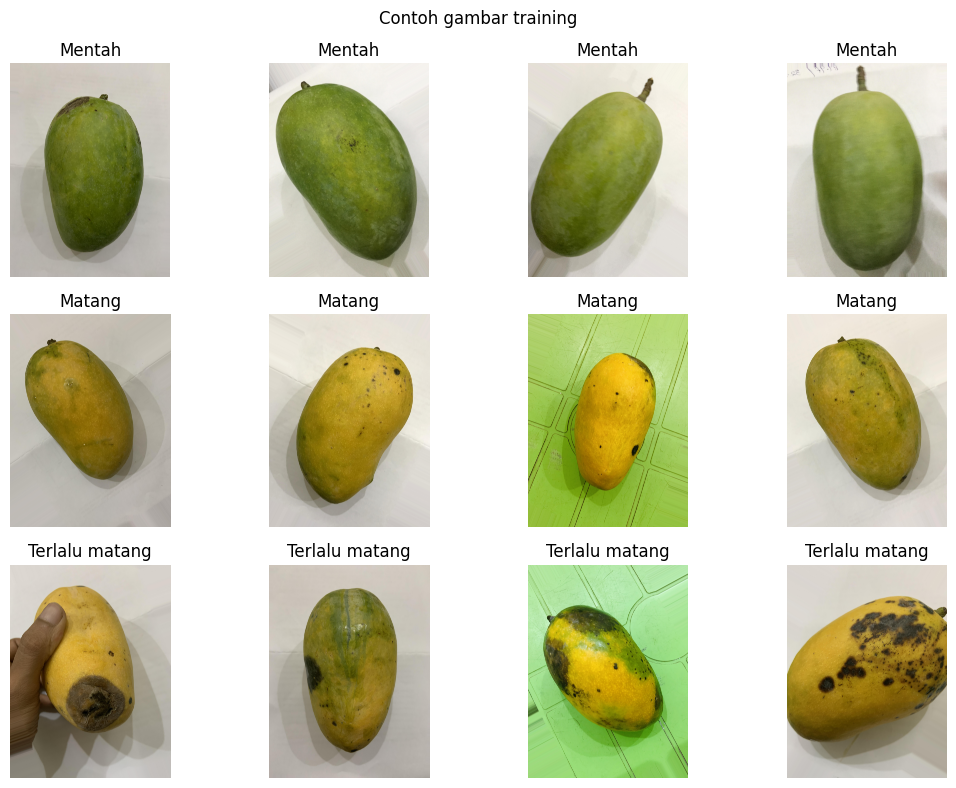

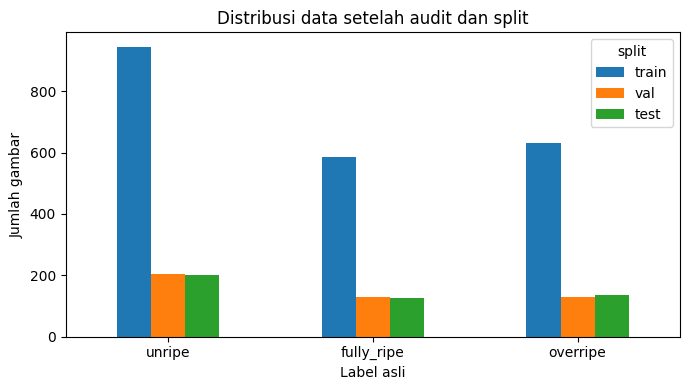

In [ ]:
# Contoh gambar hanya dari training set, test tidak dilihat untuk pemilihan model.
fig, axes = plt.subplots(3, 4, figsize=(11, 8))
for label in range(3):
    candidates = train_df[train_df.label == label].sample(min(4, sum(train_df.label == label)), random_state=SEED)
    for ax in axes[label]:
        ax.axis("off")
    for ax, (_, row) in zip(axes[label], candidates.iterrows()):
        with Image.open(row.path) as im:
            ax.imshow(ImageOps.exif_transpose(im).convert("RGB"))
        ax.set_title(DISPLAY_NAMES[label])
fig.suptitle("Contoh gambar training")
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "training_samples.png", dpi=180, bbox_inches="tight"); plt.show()
fig, ax = plt.subplots(figsize=(7, 4))
split_summary.plot(kind="bar", ax=ax, rot=0)
ax.set(xlabel="Label asli", ylabel="Jumlah gambar", title="Distribusi data setelah audit dan split")
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "class_distribution.png", dpi=180); plt.show()


### 6. Model awal dan preprocessing
Model menggunakan mobilenetv4_conv_small.e2400_r224_in1k melalui timm/PyTorch, dengan bobot ImageNet hasil pelatihan Ross Wightman. Classifier diubah menjadi tiga keluaran, dan kedua eksperimen dimulai dari bobot awal yang sama.

Semua gambar diubah menjadi 224x224 piksel dan dinormalisasi sesuai bobot pralatih. Resize langsung dapat mengubah proporsi bentuk gambar.

Baseline hanya menggunakan resize dan normalisasi. Eksperimen augmentasi menambahkan perubahan kecerahan dan kontras ±15% pada data training. Hue dan saturation tetap, sedangkan validation dan test diproses tanpa augmentasi acak.

Referensi: https://huggingface.co/timm/mobilenetv4_conv_small.e2400_r224_in1k


In [ ]:
seed_everything(SEED)
initial_path = OUTPUT_DIR / "initial_state.pt"
if initial_path.exists():
    initial_model = timm.create_model(MODEL_NAME, pretrained=False, num_classes=3, drop_rate=0.2)
    initial_model.load_state_dict(torch.load(initial_path, map_location="cpu", weights_only=True))
else:
    # Jika bobot gagal diunduh, sel berhenti; tidak diam-diam memakai bobot acak.
    initial_model = timm.create_model(MODEL_NAME, pretrained=True, num_classes=3, drop_rate=0.2)
    temp_path = initial_path.with_suffix(".tmp")
    torch.save(initial_model.state_dict(), temp_path); temp_path.replace(initial_path)
data_config = timm.data.resolve_model_data_config(initial_model)
MEAN, STD = tuple(data_config["mean"]), tuple(data_config["std"])
MODEL_INFO = {"name": MODEL_NAME, "total_parameters": sum(p.numel() for p in initial_model.parameters()),
              "classifier_parameters": sum(p.numel() for p in initial_model.get_classifier().parameters()),
              "mean": MEAN, "std": STD, "input": [3, IMG_SIZE, IMG_SIZE]}
(OUTPUT_DIR / "model_info.json").write_text(json.dumps(MODEL_INFO, indent=2))
(OUTPUT_DIR / "model_architecture.txt").write_text(str(initial_model))
display(pd.DataFrame([MODEL_INFO]))
del initial_model; gc.collect()

def make_transform(augment=False):
    steps = [T.Resize((IMG_SIZE, IMG_SIZE), interpolation=InterpolationMode.BILINEAR, antialias=True)]
    if augment:
        steps.append(T.ColorJitter(brightness=BRIGHTNESS, contrast=CONTRAST))
    return T.Compose(steps + [T.ToTensor(), T.Normalize(MEAN, STD)])

class MangoDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True).copy(); self.transform = transform
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(row.path) as im:
            image = ImageOps.exif_transpose(im).convert("RGB")
        return self.transform(image), int(row.label)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed); random.seed(worker_seed)

def make_loaders(augment):
    generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(MangoDataset(train_df, make_transform(augment)), batch_size=BATCH_SIZE,
        shuffle=True, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda",
        generator=generator, worker_init_fn=seed_worker,
        drop_last=(len(train_df) % BATCH_SIZE == 1))
    val_loader = DataLoader(MangoDataset(val_df, make_transform(False)), batch_size=BATCH_SIZE,
        shuffle=False, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda")
    return train_loader, val_loader, generator

sample_x, sample_y = MangoDataset(train_df, make_transform(False))[0]
print("Contoh tensor:", tuple(sample_x.shape), "label:", sample_y)
assert sample_x.shape == (3, IMG_SIZE, IMG_SIZE) and torch.isfinite(sample_x).all()


,name,total_parameters,classifier_parameters,mean,std,input
0,mobilenetv4_conv_small.e2400_r224_in1k,2496867,3843,"(0.485, 0.456, 0.406)","(0.229, 0.224, 0.225)","[3, 224, 224]"


Contoh tensor: (3, 224, 224) label: 1


### 7. Fungsi training, checkpoint, dan evaluasi



In [ ]:
def atomic_torch_save(obj, path):
    temporary = path.with_suffix(path.suffix + ".tmp")
    torch.save(obj, temporary); temporary.replace(path)

def configure_stage(model, stage):
    for p in model.parameters():
        p.requires_grad = (stage == "finetune")
    classifier_params = list(model.get_classifier().parameters())
    for p in classifier_params:
        p.requires_grad = True
    if stage == "head":
        return torch.optim.AdamW(classifier_params, lr=HEAD_LR, weight_decay=WEIGHT_DECAY)
    classifier_ids = {id(p) for p in classifier_params}
    backbone = [p for p in model.parameters() if id(p) not in classifier_ids]
    return torch.optim.AdamW([
        {"params": backbone, "lr": FINETUNE_LR},
        {"params": classifier_params, "lr": FINETUNE_HEAD_LR},
    ], weight_decay=WEIGHT_DECAY)

def run_epoch(model, loader, criterion, optimizer=None, scaler=None, stage="finetune"):
    training = optimizer is not None
    if training and stage == "head":
        model.eval()  # Backbone termasuk BatchNorm tetap beku.
        model.get_classifier().train()
    else:
        model.train(training)
    total_loss, n = 0.0, 0
    true, pred, probabilities = [], [], []
    with torch.set_grad_enabled(training):
        for images, targets in tqdm(loader, leave=False, desc="Train" if training else "Validation"):
            images, targets = images.to(DEVICE, non_blocking=True), targets.to(DEVICE, non_blocking=True)
            if training:
                optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda"):
                logits = model(images); loss = criterion(logits, targets)
            if not torch.isfinite(loss):
                raise RuntimeError("Loss tidak finite. Periksa data dan learning rate.")
            if training:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
                scaler.step(optimizer); scaler.update()
            batch_probs = logits.detach().float().softmax(1).cpu().numpy()
            probabilities.append(batch_probs)
            true.extend(targets.detach().cpu().tolist()); pred.extend(batch_probs.argmax(1).tolist())
            total_loss += loss.item() * len(targets); n += len(targets)
    metrics = {"loss": total_loss / n, "accuracy": accuracy_score(true, pred),
               "macro_f1": f1_score(true, pred, labels=list(range(3)), average="macro", zero_division=0)}
    return metrics, np.array(true), np.array(pred), np.concatenate(probabilities)

def save_evaluation(name, model, frame, split="val"):
    directory = OUTPUT_DIR / name
    loader = DataLoader(MangoDataset(frame, make_transform(False)), batch_size=BATCH_SIZE,
                        shuffle=False, num_workers=NUM_WORKERS)
    metrics, true, pred, probs = run_epoch(model, loader, nn.CrossEntropyLoss())
    report = classification_report(true, pred, labels=list(range(3)), target_names=CLASS_NAMES,
                                   output_dict=True, zero_division=0)
    metrics["weighted_f1"] = f1_score(true, pred, average="weighted", zero_division=0)
    (directory / f"{split}_metrics.json").write_text(json.dumps(metrics, indent=2))
    pd.DataFrame(report).T.to_csv(directory / f"{split}_classification_report.csv")
    predictions = frame.reset_index(drop=True)[["relative_path", "class_name", "label"]].copy()
    predictions["prediction"] = [CLASS_NAMES[i] for i in pred]
    predictions["correct"] = pred == true
    for i, label in enumerate(CLASS_NAMES):
        predictions[f"prob_{label}"] = probs[:, i]
    predictions.to_csv(directory / f"{split}_predictions.csv", index=False)
    cm = confusion_matrix(true, pred, labels=list(range(3)))
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=DISPLAY_NAMES, yticklabels=DISPLAY_NAMES, ax=ax)
    ax.set(xlabel="Prediksi", ylabel="Label asli", title=f"{name} — {split}")
    fig.tight_layout(); fig.savefig(directory / f"{split}_confusion_matrix.png", dpi=200); plt.show()
    print(classification_report(true, pred, labels=list(range(3)), target_names=CLASS_NAMES, zero_division=0))
    return metrics

def plot_history(name):
    directory = OUTPUT_DIR / name
    history = pd.read_csv(directory / "history.csv")
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, metric in zip(axes, ["loss", "accuracy", "macro_f1"]):
        ax.plot(history.epoch, history[f"train_{metric}"], label="Training")
        ax.plot(history.epoch, history[f"val_{metric}"], label="Validation")
        ax.axvline(HEAD_EPOCHS + 0.5, color="gray", linestyle="--", linewidth=1)
        ax.set(xlabel="Epoch", ylabel=metric, title=metric); ax.legend()
    fig.suptitle(name); fig.tight_layout()
    fig.savefig(directory / "learning_curves.png", dpi=200); plt.show()

def train_experiment(name, augment=False):
    directory = OUTPUT_DIR / name
    directory.mkdir(parents=True, exist_ok=True)
    completed_path = directory / "completed.json"
    if completed_path.exists():
        completed = json.loads(completed_path.read_text())
        if completed["config_hash"] != CONFIG_HASH:
            raise RuntimeError("Checkpoint berbeda konfigurasi. Ganti RUN_NAME.")
        print(name, "sudah selesai; membaca hasil tersimpan.")
        plot_history(name)
        return json.loads((directory / "val_metrics.json").read_text())
    seed_everything(SEED)
    model = timm.create_model(MODEL_NAME, pretrained=False, num_classes=3, drop_rate=0.2).to(DEVICE)
    model.load_state_dict(torch.load(initial_path, map_location=DEVICE, weights_only=True))
    train_loader, val_loader, generator = make_loaders(augment)
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda")
    criterion = nn.CrossEntropyLoss()
    history, start_epoch, best_f1, best_loss = [], 0, -1.0, float("inf")
    last_path = directory / "last_checkpoint.pt"
    resume = None
    if last_path.exists():
        # weights_only=False hanya untuk checkpoint internal berisi RNG NumPy/Python.
        resume = torch.load(last_path, map_location="cpu", weights_only=False)
        if resume["config_hash"] != CONFIG_HASH or resume["augment"] != augment:
            raise RuntimeError("Konfigurasi checkpoint berbeda. Ganti RUN_NAME.")
        model.load_state_dict(resume["model"])
        history, start_epoch = resume["history"], resume["epoch"]
        best_f1, best_loss = resume["best_f1"], resume["best_loss"]
        random.setstate(resume["python_rng"]); np.random.set_state(resume["numpy_rng"])
        torch.set_rng_state(resume["torch_rng"])
        if DEVICE.type == "cuda" and resume["cuda_rng"] is not None:
            torch.cuda.set_rng_state_all(resume["cuda_rng"])
        generator.set_state(resume["loader_rng"])
        scaler.load_state_dict(resume["scaler"])
        print(f"Melanjutkan {name} dari epoch {start_epoch + 1}.")
    optimizer, current_stage = None, None
    for epoch in range(start_epoch, HEAD_EPOCHS + FINETUNE_EPOCHS):
        stage = "head" if epoch < HEAD_EPOCHS else "finetune"
        if stage != current_stage:
            optimizer = configure_stage(model, stage)
            if resume is not None and resume["stage"] == stage:
                optimizer.load_state_dict(resume["optimizer"])
                # State optimizer perlu berada pada device yang sama dengan parameter.
                for state in optimizer.state.values():
                    for key, value in state.items():
                        if torch.is_tensor(value) and key != "step":
                            state[key] = value.to(DEVICE)
            current_stage = stage
            resume = None
        started = time.perf_counter()
        train_metrics, _, _, _ = run_epoch(model, train_loader, criterion, optimizer, scaler, stage)
        val_metrics, _, _, _ = run_epoch(model, val_loader, criterion)
        row = {"epoch": epoch + 1, "stage": stage, "seconds": time.perf_counter() - started,
               **{f"train_{k}": v for k, v in train_metrics.items()},
               **{f"val_{k}": v for k, v in val_metrics.items()}}
        history.append(row)
        improved = val_metrics["macro_f1"] > best_f1 or (
            val_metrics["macro_f1"] == best_f1 and val_metrics["loss"] < best_loss)
        if improved:
            best_f1, best_loss = val_metrics["macro_f1"], val_metrics["loss"]
            atomic_torch_save({"state_dict": model.state_dict(), "model_name": MODEL_NAME,
                "classes": CLASS_NAMES, "epoch": epoch + 1, "config_hash": CONFIG_HASH,
                "metrics": val_metrics, "preprocessing": MODEL_INFO}, directory / "best_model.pt")
        atomic_torch_save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
            "scaler": scaler.state_dict(), "epoch": epoch + 1, "stage": stage,
            "history": history, "best_f1": best_f1, "best_loss": best_loss,
            "config_hash": CONFIG_HASH, "augment": augment,
            "python_rng": random.getstate(), "numpy_rng": np.random.get_state(),
            "torch_rng": torch.get_rng_state(),
            "cuda_rng": torch.cuda.get_rng_state_all() if DEVICE.type == "cuda" else None,
            "loader_rng": generator.get_state()}, last_path)
        pd.DataFrame(history).to_csv(directory / "history.csv", index=False)
        print(f"{name} | {epoch + 1:02d}/{HEAD_EPOCHS + FINETUNE_EPOCHS} {stage} | "
              f"train loss={train_metrics['loss']:.4f}, acc={train_metrics['accuracy']:.4f} | "
              f"val loss={val_metrics['loss']:.4f}, acc={val_metrics['accuracy']:.4f}, "
              f"macro F1={val_metrics['macro_f1']:.4f}")
    checkpoint = torch.load(directory / "best_model.pt", map_location=DEVICE, weights_only=True)
    model.load_state_dict(checkpoint["state_dict"])
    metrics = save_evaluation(name, model, val_df, "val")
    plot_history(name)
    completed_path.write_text(json.dumps({"config_hash": CONFIG_HASH, "best_epoch": checkpoint["epoch"],
                                          "augment": augment, "epochs_completed": len(history)}, indent=2))
    del model, optimizer, scaler, train_loader, val_loader
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return metrics


### 8. Test 1 - baseline


Train:   0%|          | 0/68 [00:00<?, ?it/s]

Validation:   0%|          | 0/15 [00:00<?, ?it/s]

baseline | 01/10 head | train loss=2.2672, acc=0.6438 | val loss=1.0382, acc=0.7430, macro F1=0.6932


Train:   0%|          | 0/68 [00:00<?, ?it/s]

Validation:   0%|          | 0/15 [00:00<?, ?it/s]

baseline | 02/10 head | train loss=0.7556, acc=0.8002 | val loss=0.4720, acc=0.8510, macro F1=0.8273


... (21 outputs left out)

Train:   0%|          | 0/68 [00:00<?, ?it/s]

Validation:   0%|          | 0/15 [00:00<?, ?it/s]

baseline | 10/10 finetune | train loss=0.1318, acc=0.9746 | val loss=0.3126, acc=0.9611, macro F1=0.9537


Validation:   0%|          | 0/15 [00:00<?, ?it/s]

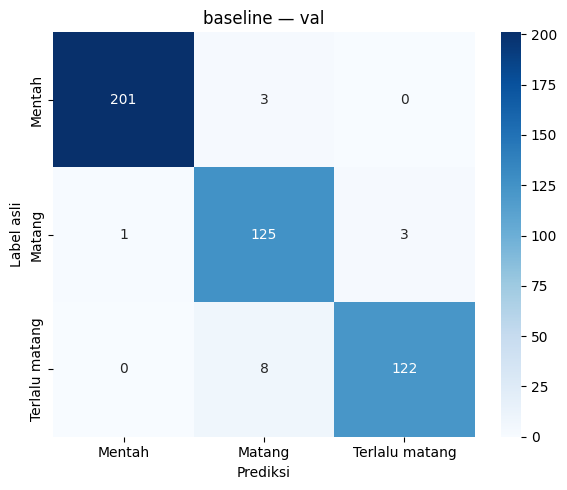

              precision    recall  f1-score   support

      unripe       1.00      0.99      0.99       204
  fully_ripe       0.92      0.97      0.94       129
    overripe       0.98      0.94      0.96       130

    accuracy                           0.97       463
   macro avg       0.96      0.96      0.96       463
weighted avg       0.97      0.97      0.97       463



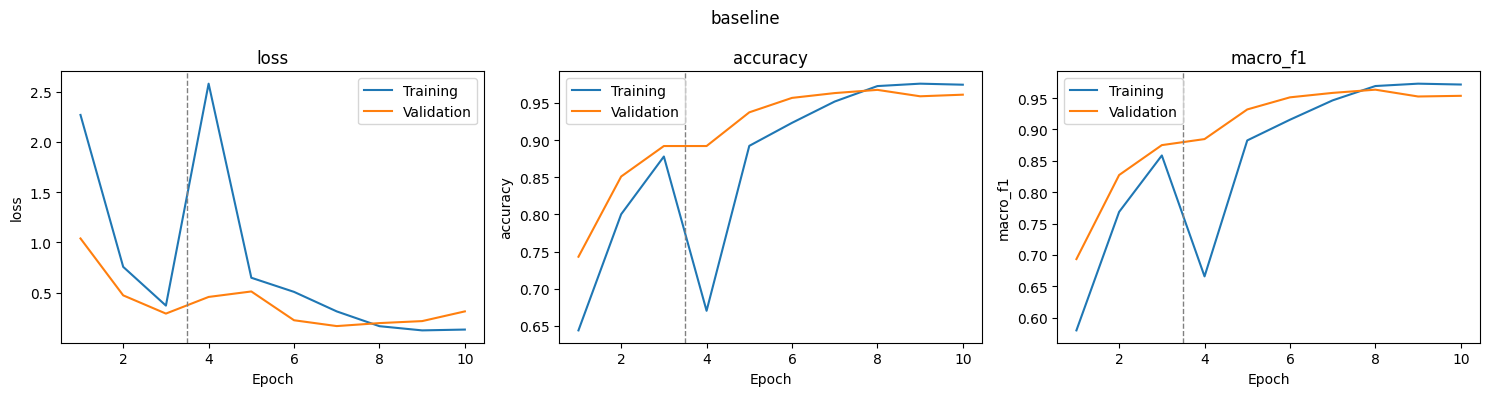

,loss,accuracy,macro_f1,weighted_f1
baseline_validation,0.196169,0.967603,0.963469,0.967776


In [ ]:
baseline_metrics = train_experiment("baseline", augment=False)
display(pd.DataFrame([baseline_metrics], index=["baseline_validation"]))


### 9. Test 2 - augmentasi brightness/contrast



Train:   0%|          | 0/68 [00:00<?, ?it/s]

Validation:   0%|          | 0/15 [00:00<?, ?it/s]

brightness_contrast | 01/10 head | train loss=2.1128, acc=0.6573 | val loss=0.9790, acc=0.7473, macro F1=0.7075


Train:   0%|          | 0/68 [00:00<?, ?it/s]

Validation:   0%|          | 0/15 [00:00<?, ?it/s]

brightness_contrast | 02/10 head | train loss=0.7627, acc=0.7993 | val loss=0.4724, acc=0.8359, macro F1=0.8110


... (22 outputs left out)

Train:   0%|          | 0/68 [00:00<?, ?it/s]

Validation:   0%|          | 0/15 [00:00<?, ?it/s]

brightness_contrast | 10/10 finetune | train loss=0.2018, acc=0.9672 | val loss=0.2090, acc=0.9719, macro F1=0.9665


Validation:   0%|          | 0/15 [00:00<?, ?it/s]

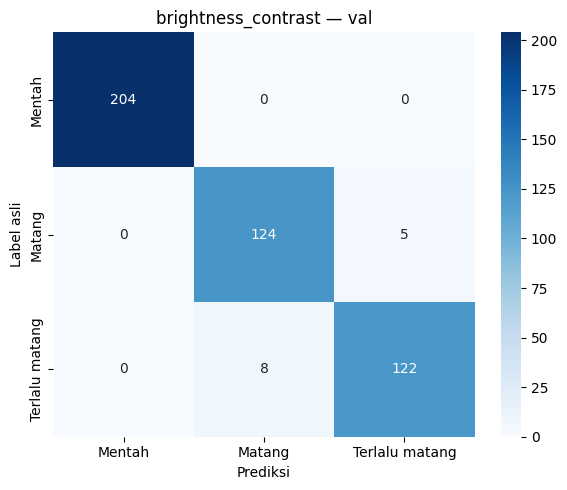

              precision    recall  f1-score   support

      unripe       1.00      1.00      1.00       204
  fully_ripe       0.94      0.96      0.95       129
    overripe       0.96      0.94      0.95       130

    accuracy                           0.97       463
   macro avg       0.97      0.97      0.97       463
weighted avg       0.97      0.97      0.97       463



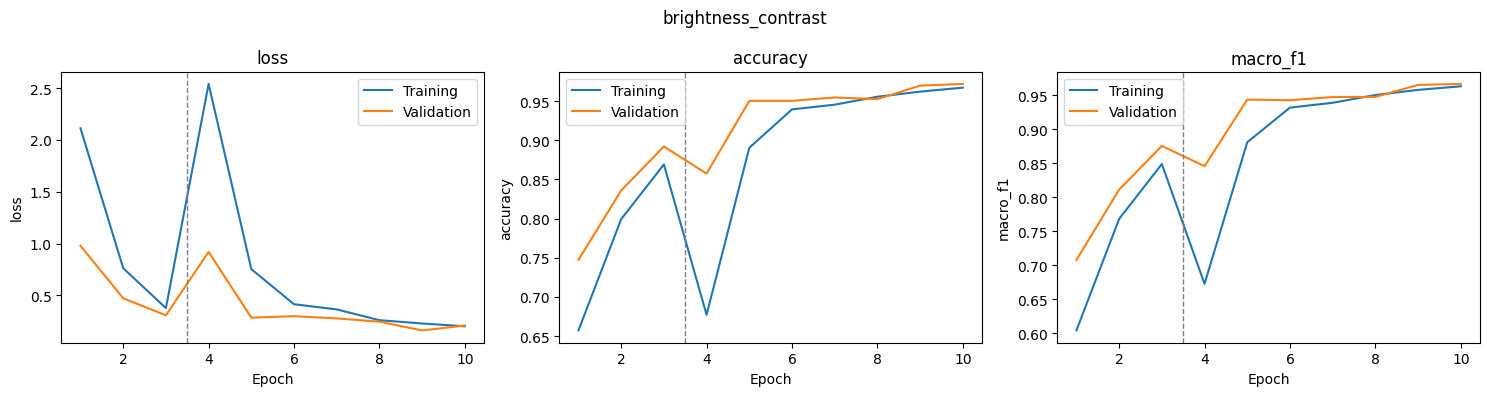

,loss,accuracy,macro_f1,weighted_f1
augmented_validation,0.209007,0.971922,0.966536,0.97192


In [ ]:
if RUN_AUGMENTED:
    augmented_metrics = train_experiment("brightness_contrast", augment=True)
    display(pd.DataFrame([augmented_metrics], index=["augmented_validation"]))
else:
    print("Eksperimen augmentasi belum dijalankan; tulis sebagai pekerjaan lanjutan.")


### 10. Tabel perbandingan dan contoh kesalahan validation



,experiment,evaluation_split,loss,accuracy,macro_f1,weighted_f1,best_epoch,epochs_completed,training_minutes
0,baseline,validation,0.125484,0.980562,0.976833,0.980561,10,10,63.631497
1,brightness_contrast,validation,0.209007,0.971922,0.966536,0.971920,10,10,63.518066


Dipilih berdasarkan validation macro F1: baseline
Selisih macro F1 augmentasi - baseline: -0.0103 (-1.03 poin persentase)


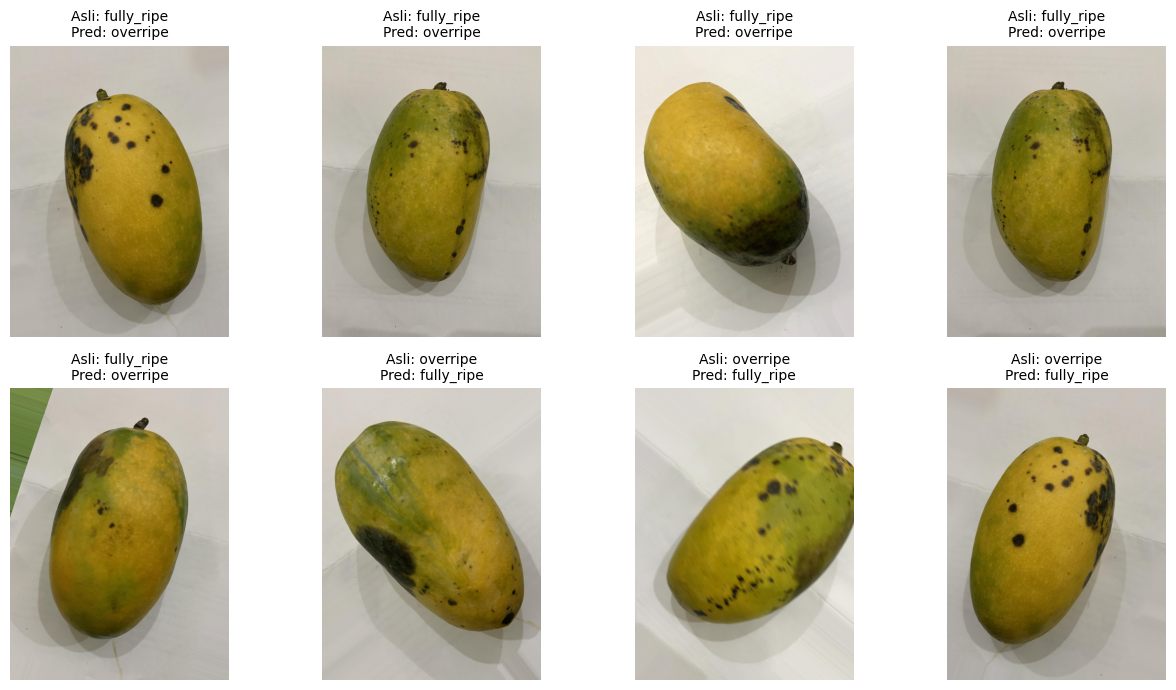

# Ringkasan hasil awal — Klasifikasi Kematangan Mangga

Anggota: Felix Ferdinad, Melvyn Benaya Wijaya | NIM: 535230123, 535230047

URL Colab: Belum diisi

Dataset: Mashkoor & Hakim (2024), Mango Shelf-Life Dataset V1. https://data.mendeley.com/datasets/rk4mm635rn/1

DOI: 10.17632/rk4mm635rn.1 | Lisensi: CC BY 4.0 | White Chaunsa Late, Multan, Pakistan.

Kelas yang dipakai: unripe, fully ripe, overripe. Semi-ripe/perished dikeluarkan.

Gambar valid sebelum deduplikasi: 3087; duplikat identik dibuang: 0; gambar rusak: 0; gambar digunakan: 3087.

Split aktual: train=2162 (70.0%), val=463 (15.0%), test=462 (15.0%)

Grup split: 2327; grouping pHash threshold=4; ID buah tersedia=False.

Model: mobilenetv4_conv_small.e2400_r224_in1k, pralatih ImageNet (timm), classifier 3 kelas, input 224x224.

Training: seed=42, batch=32, AdamW, cross-entropy; 3 epoch classifier (lr=0.001) + 7 epoch fine-tuning (backbone lr=3e-05, classifier lr=0.0003).

Augmentasi kondisi kedua: brightness +/-15%, contrast +/-15%, hanya training.

Pemilihan checkpoint: validation macro F1 tertinggi; tie berdasarkan loss lebih rendah.

## Hasil pada validation (hasil awal)

- baseline: accuracy=0.9806, macro F1=0.9768, weighted F1=0.9806; epoch terbaik=10; epoch selesai=10; waktu training=63.6 menit.

- brightness_contrast: accuracy=0.9719, macro F1=0.9665, weighted F1=0.9719; epoch terbaik=10; epoch selesai=10; waktu training=63.5 menit.

## Keterbatasan dan pekerjaan berikutnya

Satu seed per kondisi. pHash adalah heuristik dan tidak membuktikan independensi antarbuah. Foto buah/sesi yang sama mungkin masih berkorelasi jika ID tidak tersedia. Satu varietas dari Pakistan belum mewakili variasi mangga UMKM Indonesia. Label berasal dari dataset dan belum diverifikasi melalui uji kematangan internal.

Langkah berikutnya: audit grup dan label, ulangi beberapa seed, kunci konfigurasi, evaluasi test sekali, lalu uji foto eksternal pada pencahayaan dan varietas berbeda.

Test belum dievaluasi oleh sel perbandingan ini. Jangan menyebut hasil validation sebagai test accuracy.

In [ ]:
records = []
for name in ["baseline"] + (["brightness_contrast"] if RUN_AUGMENTED else []):
    directory = OUTPUT_DIR / name
    if not (directory / "completed.json").exists():
        continue
    metrics = json.loads((directory / "val_metrics.json").read_text())
    complete = json.loads((directory / "completed.json").read_text())
    history = pd.read_csv(directory / "history.csv")
    records.append({"experiment": name, "evaluation_split": "validation", **metrics,
                    "best_epoch": complete["best_epoch"], "epochs_completed": complete["epochs_completed"],
                    "training_minutes": history.seconds.sum() / 60})
comparison = pd.DataFrame(records).sort_values(["macro_f1", "loss"], ascending=[False, True]).reset_index(drop=True)
comparison.to_csv(OUTPUT_DIR / "validation_comparison.csv", index=False)
display(comparison)
SELECTED_EXPERIMENT = comparison.iloc[0].experiment
print("Dipilih berdasarkan validation macro F1:", SELECTED_EXPERIMENT)
if len(comparison) == 2:
    by_name = comparison.set_index("experiment")
    delta = by_name.loc["brightness_contrast", "macro_f1"] - by_name.loc["baseline", "macro_f1"]
    print(f"Selisih macro F1 augmentasi - baseline: {delta:+.4f} ({delta * 100:+.2f} poin persentase)")

predictions = pd.read_csv(OUTPUT_DIR / SELECTED_EXPERIMENT / "val_predictions.csv")
wrong = predictions[~predictions.correct].head(8)
if len(wrong):
    fig, axes = plt.subplots(2, 4, figsize=(13, 7))
    for ax in axes.flat:
        ax.axis("off")
    for ax, (_, row) in zip(axes.flat, wrong.iterrows()):
        with Image.open(DATA_ROOT / row.relative_path) as im:
            ax.imshow(ImageOps.exif_transpose(im).convert("RGB"))
        ax.set_title(f"Asli: {row.class_name}\nPred: {row.prediction}", fontsize=10)
    fig.tight_layout(); fig.savefig(OUTPUT_DIR / "validation_errors.png", dpi=180); plt.show()
else:
    print("Tidak ada kesalahan pada validation; tetap audit kemiripan data dan uji data eksternal.")

summary = [
    "# Ringkasan hasil awal — Klasifikasi Kematangan Mangga",
    f"Anggota: {AUTHOR_NAMES} | NIM: {STUDENT_IDS}", f"URL Colab: {COLAB_URL or 'Belum diisi'}",
    f"Dataset: Mashkoor & Hakim (2024), Mango Shelf-Life Dataset V1. {DATASET_URL}",
    "DOI: 10.17632/rk4mm635rn.1 | Lisensi: CC BY 4.0 | White Chaunsa Late, Multan, Pakistan.",
    "Kelas yang dipakai: unripe, fully ripe, overripe. Semi-ripe/perished dikeluarkan.",
    f"Gambar valid sebelum deduplikasi: {len(raw_df)}; duplikat identik dibuang: {len(duplicates)}; "
    f"gambar rusak: {len(invalid)}; gambar digunakan: {len(df)}.",
    "Split aktual: " + ", ".join(f"{s}={len(f)} ({len(f)/len(df):.1%})" for s, f in parts.items()),
    f"Grup split: {df.group_id.nunique()}; grouping pHash threshold={PHASH_DISTANCE}; ID buah tersedia={bool(GROUP_CSV)}.",
    f"Model: {MODEL_NAME}, pralatih ImageNet (timm), classifier 3 kelas, input {IMG_SIZE}x{IMG_SIZE}.",
    f"Training: seed={SEED}, batch={BATCH_SIZE}, AdamW, cross-entropy; "
    f"{HEAD_EPOCHS} epoch classifier (lr={HEAD_LR}) + {FINETUNE_EPOCHS} epoch fine-tuning "
    f"(backbone lr={FINETUNE_LR}, classifier lr={FINETUNE_HEAD_LR}).",
    f"Augmentasi kondisi kedua: brightness +/-{BRIGHTNESS:.0%}, contrast +/-{CONTRAST:.0%}, hanya training.",
    "Pemilihan checkpoint: validation macro F1 tertinggi; tie berdasarkan loss lebih rendah.",
    "## Hasil pada validation (hasil awal)",
]
for row in comparison.itertuples():
    summary.append(f"- {row.experiment}: accuracy={row.accuracy:.4f}, macro F1={row.macro_f1:.4f}, "
                   f"weighted F1={row.weighted_f1:.4f}; epoch terbaik={row.best_epoch}; "
                   f"epoch selesai={row.epochs_completed}; waktu training={row.training_minutes:.1f} menit.")
summary.extend([
    "## Keterbatasan dan pekerjaan berikutnya",
    "Satu seed per kondisi. pHash adalah heuristik dan tidak membuktikan independensi antarbuah. "
    "Foto buah/sesi yang sama mungkin masih berkorelasi jika ID tidak tersedia. "
    "Satu varietas dari Pakistan belum mewakili variasi mangga UMKM Indonesia. "
    "Label berasal dari dataset dan belum diverifikasi melalui uji kematangan internal.",
    "Langkah berikutnya: audit grup dan label, ulangi beberapa seed, kunci konfigurasi, "
    "evaluasi test sekali, lalu uji foto eksternal pada pencahayaan dan varietas berbeda.",
    "Test belum dievaluasi oleh sel perbandingan ini. Jangan menyebut hasil validation sebagai test accuracy.",
])
(OUTPUT_DIR / "progress_summary.md").write_text("\n\n".join(summary))
display(Markdown((OUTPUT_DIR / "progress_summary.md").read_text()))


### 11. Evaluasi test setelah konfigurasi dikunci


In [ ]:
if RUN_FINAL_TEST:
    test_record = OUTPUT_DIR / "final_test_record.json"
    if test_record.exists():
        record = json.loads(test_record.read_text())
        if record["config_hash"] != CONFIG_HASH or record["experiment"] != SELECTED_EXPERIMENT:
            raise RuntimeError("Test pernah digunakan untuk pilihan berbeda. Jangan tuning memakai test.")
        print("Hasil test tersimpan:", record)
    else:
        model = timm.create_model(MODEL_NAME, pretrained=False, num_classes=3, drop_rate=0.2).to(DEVICE)
        checkpoint = torch.load(OUTPUT_DIR / SELECTED_EXPERIMENT / "best_model.pt", map_location=DEVICE, weights_only=True)
        model.load_state_dict(checkpoint["state_dict"])
        test_metrics = save_evaluation(SELECTED_EXPERIMENT, model, test_df, "test")
        record = {"config_hash": CONFIG_HASH, "experiment": SELECTED_EXPERIMENT, "test_metrics": test_metrics}
        test_record.write_text(json.dumps(record, indent=2))
        del model; gc.collect()
        print(record)
    test_section = "\n\n## Evaluasi test final\n\n" + json.dumps(record, indent=2)
    with (OUTPUT_DIR / "progress_summary.md").open("a") as f:
        f.write(test_section)
else:
    print("Test disimpan untuk evaluasi akhir; belum dijalankan.")


Test disimpan untuk evaluasi akhir; belum dijalankan.


### 12. Prediksi satu foto baru



In [ ]:
RUN_SINGLE_IMAGE = False
if RUN_SINGLE_IMAGE:
    if not IN_COLAB:
        raise RuntimeError("Upload interaktif ini khusus Colab.")
    from google.colab import files
    uploads = files.upload()
    model = timm.create_model(MODEL_NAME, pretrained=False, num_classes=3, drop_rate=0.2).to(DEVICE)
    checkpoint = torch.load(OUTPUT_DIR / SELECTED_EXPERIMENT / "best_model.pt", map_location=DEVICE, weights_only=True)
    model.load_state_dict(checkpoint["state_dict"]); model.eval()
    for filename in uploads:
        with Image.open(filename) as im:
            image = ImageOps.exif_transpose(im).convert("RGB")
        with torch.inference_mode():
            scores = model(make_transform(False)(image).unsqueeze(0).to(DEVICE)).softmax(1)[0].cpu().numpy()
        display(image.resize((300, 300)))
        display(pd.DataFrame({"kelas": DISPLAY_NAMES, "softmax_score": scores}))
        print("Prediksi:", DISPLAY_NAMES[int(scores.argmax())])
    del model


### 13. Simpan paket hasil test



In [ ]:
bundle_path = OUTPUT_DIR.parent / f"{RUN_NAME}_results.zip"
with zipfile.ZipFile(bundle_path, "w", zipfile.ZIP_DEFLATED) as bundle:
    for path in sorted(OUTPUT_DIR.rglob("*")):
        if path.is_file() and path.name not in {"last_checkpoint.pt", "initial_state.pt"} and not path.name.endswith(".tmp"):
            bundle.write(path, arcname=str(path.relative_to(OUTPUT_DIR)))
print("Paket hasil:", bundle_path)
print("Bahan laporan: progress_summary.md, validation_comparison.csv, dataset_split_summary.csv,")
print("learning_curves.png, val_confusion_matrix.png, dan val_classification_report.csv.")
DOWNLOAD_RESULTS = True
if DOWNLOAD_RESULTS and IN_COLAB:
    from google.colab import files
    files.download(str(bundle_path))


Paket hasil: /content/drive/MyDrive/UAS_DeepLearning_Mangga/test_01_results.zip
Bahan laporan: progress_summary.md, validation_comparison.csv, dataset_split_summary.csv,
learning_curves.png, val_confusion_matrix.png, dan val_classification_report.csv.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>